In [ ]:
import pandas as pd

In [ ]:
from sklearn.preprocessing import MinMaxScaler

data = pd.DataFrame({
    'A': [10, 20, 30, 40, 50],
    'B': [5, 15, 25, 35, 45]})
print(data)

scaler = MinMaxScaler()
normalized_data = scaler.fit_transform(data)

normalized_df = pd.DataFrame(normalized_data, columns= data.columns)

print("Normalized Data (Min-Max Scaling):")
print(normalized_df)


    A   B
0  10   5
1  20  15
2  30  25
3  40  35
4  50  45
Normalized Data (Min-Max Scaling):
      A     B
0  0.00  0.00
1  0.25  0.25
2  0.50  0.50
3  0.75  0.75
4  1.00  1.00


In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
standardized_data = scaler.fit_transform(data)

standardized_df = pd.DataFrame(standardized_data, columns = data.columns)

print("\nStandardized Data (Z-score):")
print(standardized_df)


Standardized Data (Z-score):
          A         B
0 -1.414214 -1.414214
1 -0.707107 -0.707107
2  0.000000  0.000000
3  0.707107  0.707107
4  1.414214  1.414214


In [ ]:
df = pd.DataFrame({'Color': ['Red', 'Blue', 'Green', 'Red', 'Blue']})

one_hot = pd.get_dummies(df['Color'], prefix = 'Color')

print("\nOne-Hot Encoding:")
print(one_hot)


One-Hot Encoding:
   Color_Blue  Color_Green  Color_Red
0       False        False       True
1        True        False      False
2       False         True      False
3       False        False       True
4        True        False      False


In [ ]:
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler, StandardScaler, LabelEncoder

tips = sns.load_dataset("tips")

print("Original Data (first 5 rows):")
print(tips.head())

numeric_cols = tips.select_dtypes(include=['float64','int64']).columns

scaler = MinMaxScaler()
tips_normalized = tips.copy()
tips_normalized[numeric_cols] = scaler.fit_transform(tips[numeric_cols])

print("\nNormalized Data (first 5 rows):")
print(tips_normalized.head())

scaler = StandardScaler()
tips_standardized = tips.copy()
tips_standardized[numeric_cols] = scaler.fit_transform(tips[numeric_cols])

print("\nStandardized Data (first 5 rows):")
print(tips_standardized.head())

label = LabelEncoder()
tips['day_encoded'] = label.fit_transform(tips['day'])

print("\nEncoded Data (first 5 rows):")
print(tips.head())

Original Data (first 5 rows):
   total_bill   tip     sex smoker  day    time  size
0       16.99  1.01  Female     No  Sun  Dinner     2
1       10.34  1.66    Male     No  Sun  Dinner     3
2       21.01  3.50    Male     No  Sun  Dinner     3
3       23.68  3.31    Male     No  Sun  Dinner     2
4       24.59  3.61  Female     No  Sun  Dinner     4

Normalized Data (first 5 rows):
   total_bill       tip     sex smoker  day    time  size
0    0.291579  0.001111  Female     No  Sun  Dinner   0.2
1    0.152283  0.073333    Male     No  Sun  Dinner   0.4
2    0.375786  0.277778    Male     No  Sun  Dinner   0.4
3    0.431713  0.256667    Male     No  Sun  Dinner   0.2
4    0.450775  0.290000  Female     No  Sun  Dinner   0.6

Standardized Data (first 5 rows):
   total_bill       tip     sex smoker  day    time      size
0   -0.314711 -1.439947  Female     No  Sun  Dinner -0.600193
1   -1.063235 -0.969205    Male     No  Sun  Dinner  0.453383
2    0.137780  0.363356    Male     No  Sun 

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import seaborn as sns
import pandas as pd

tips = sns.load_dataset("tips")

numeric_cols = tips.select_dtypes(include=['float64','int64']).columns

scaler = StandardScaler()
scaled_data = scaler.fit_transform(tips[numeric_cols])

pca = PCA(n_components = 2)
pca_result = pca.fit_transform(scaled_data)

pca_df = pd.DataFrame(data = pca_result, columns = ['PC1', 'PC2'])

print("Explained variance ratio:", pca.explained_variance_ratio_)
print("\nPCA Result (first 5 rows):")
print(pca_df.head())

Explained variance ratio: [0.72627656 0.1730423 ]

PCA Result (first 5 rows):
        PC1       PC2
0 -1.348415  0.426746
1 -0.955740  1.093576
2  0.540971  0.122324
3  0.067789 -0.674616
4  1.408308  0.847661


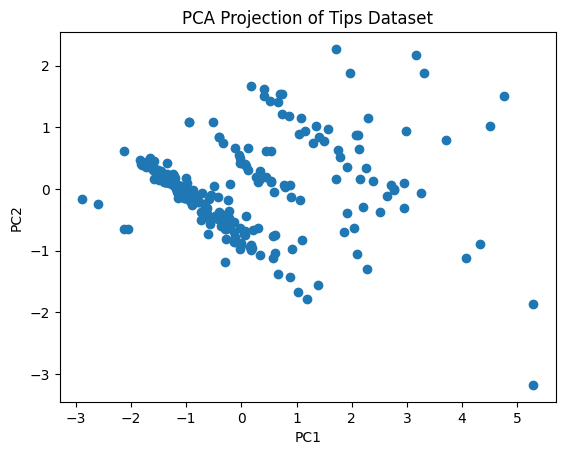

In [ ]:
import matplotlib.pyplot as plt

plt.scatter(pca_df['PC1'], pca_df['PC2'])
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('PCA Projection of Tips Dataset')
plt.show()
